# ORIE 5256 Team Project: Numerai Tournament Entry

Full pipeline from data download to validation CORR and the model file submitted to Numerai.

**Model:** `group_3_xl_mt` · **Data:** Numerai v6.0 · **Final model:** LightGBM on the medium feature set (experiment E2)

Run top to bottom in Google Colab (High-RAM runtime recommended). Total run time is roughly 2-3 hours, mostly LightGBM training.

## 0. Setup

Install packages. `numerai-tools` provides Numerai's official scoring functions.

In [1]:
!pip install -q --upgrade numerapi pyarrow lightgbm scikit-learn scipy matplotlib
!pip install -q --no-deps numerai-tools==0.7.2
!pip install -q cloudpickle==3.1.1

Data is cached in Google Drive (`MyDrive/numerai_data`). `numerapi` skips a file that already exists with the same size, so later runs and teammates with a shortcut to the shared folder do not download again. Outside Colab, a local `numerai_data/` folder is used.

In [2]:
import os

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/numerai_data"
except ImportError:
    DATA_DIR = "numerai_data"
os.makedirs(DATA_DIR, exist_ok=True)
os.chdir(DATA_DIR)
print(os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/numerai_data


## 1. Download the data

Training data (before 2019), validation data (2019-2026), the neutralizer matrix used for NCORR, and the feature metadata.

In [3]:
import json
from numerapi import NumerAPI

napi = NumerAPI()
DATA_VERSION = "v6.0"
print(sorted({d.split("/")[0] for d in napi.list_datasets()}))

for f in ["features.json", "train.parquet", "validation.parquet", "validation_neutralizer.parquet"]:
    napi.download_dataset(f"{DATA_VERSION}/{f}")

feature_metadata = json.load(open(f"{DATA_VERSION}/features.json"))
feature_sets = feature_metadata["feature_sets"]
for name in ["small", "medium", "all"]:
    print(name, len(feature_sets[name]))

['v6.0']


v6.0/features.json: 100%|██████████| 47.9k/47.9k [00:00<00:00, 456kB/s]
v6.0/train.parquet: 100%|██████████| 2.18G/2.18G [04:11<00:00, 8.65MB/s]
v6.0/validation.parquet: 100%|██████████| 1.41G/1.41G [04:58<00:00, 4.71MB/s]
v6.0/validation_neutralizer.parquet: 100%|██████████| 4.69G/4.69G [10:30<00:00, 7.44MB/s]

small 101
medium 351
all 1040


## 2. Load training data

Two design choices, both from López de Prado, *Advances in Financial Machine Learning* (AFML):

- **Sample by date, not by row (AFML ch. 4).** The target looks 60 business days ahead, so labels on neighbouring weekly dates overlap heavily. We keep every 4th date with all of its stocks. This preserves each date's full cross-section, which is what CORR scores, and cuts memory about 4x.
- **E0 baseline.** For comparison we also rebuild the official starter sample: 200,000 random rows, small feature set.

The auxiliary targets for E3 are the 20-day targets listed in `features.json`.

In [4]:
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from numerai_tools.scoring import numerai_corr, neutral_correlation

all_targets = feature_metadata["targets"]
print(all_targets)
AUX_TARGETS = [t for t in all_targets if t.endswith("_20") and t not in ("target", "target_jupiter_60")][:2]
print("aux targets:", AUX_TARGETS)

small_features = [f for f in feature_sets["small"] if f != "feature_country"]
medium_features = [f for f in feature_sets["medium"] if f != "feature_country"]
load_features = list(dict.fromkeys(small_features + medium_features))
print(len(small_features), len(medium_features))

train_dates = sorted(pd.read_parquet(f"{DATA_VERSION}/train.parquet", columns=["date"])["date"].unique())
sampled_dates = list(train_dates[::4])
train = pd.read_parquet(
    f"{DATA_VERSION}/train.parquet",
    columns=["numerai_ticker", "date", "target"] + AUX_TARGETS + load_features,
    filters=[("date", "in", sampled_dates)],
)
last_train_date = pd.Timestamp(train_dates[-1])
print(train.shape, train["date"].nunique(), "dates")

train_e0 = pd.read_parquet(
    f"{DATA_VERSION}/train.parquet",
    columns=["numerai_ticker", "date", "target"] + small_features,
).dropna(subset=["target"])
train_e0 = train_e0.sample(n=min(200_000, len(train_e0)), random_state=7)
print(train_e0.shape)

['target', 'target_raw_return_20', 'target_raw_return_60', 'target_factor_neutral_20', 'target_factor_neutral_60', 'target_factor_feat_neutral_20', 'target_factor_feat_neutral_60', 'target_camille_20', 'target_camille_60', 'target_sydney_20', 'target_sydney_60', 'target_irina_20', 'target_irina_60', 'target_alexandra_20', 'target_alexandra_60', 'target_colleen_20', 'target_colleen_60', 'target_jean_20', 'target_jean_60', 'target_eleven_4', 'target_eleven_20', 'target_eleven_60', 'target_jupiter_20', 'target_jupiter_60']
aux targets: ['target_raw_return_20', 'target_factor_neutral_20']
100 350
(1082697, 355) 209 dates
(200000, 103)


## 3. Experiments

Fixed in advance; no other configurations were tried, so the selected model is not the best of many attempts (AFML ch. 11-14 on backtest overfitting).

| Experiment | Change |
| --- | --- |
| E0 | Official starter: random 200k rows, small features, 300 trees, learning rate 0.05 |
| E1 | E0 but every 4th date with all stocks |
| E2 | E1 with medium features, 2,000 trees, learning rate 0.01 |
| E3 | E2 plus models on two auxiliary targets, prediction ranks averaged |

All models: LightGBM, `max_depth=5`, `num_leaves=31`, `colsample_bytree=0.1`.

In [5]:
def train_model(df, features, target, n_estimators, learning_rate):
    d = df.dropna(subset=[target])
    m = lgb.LGBMRegressor(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=5,
        num_leaves=2**5 - 1,
        colsample_bytree=0.1,
        verbosity=-1,
    )
    m.fit(d[features], d[target])
    return m

experiments = {}
experiments["E0_starter"] = {"features": small_features, "targets": ["target"], "n_estimators": 300, "learning_rate": 0.05}
experiments["E1_date_sampled_small"] = {"features": small_features, "targets": ["target"], "n_estimators": 300, "learning_rate": 0.05}
experiments["E2_medium_slow"] = {"features": medium_features, "targets": ["target"], "n_estimators": 2000, "learning_rate": 0.01}
experiments["E3_medium_slow_multi_target"] = {"features": medium_features, "targets": ["target"] + AUX_TARGETS, "n_estimators": 2000, "learning_rate": 0.01}

trained = {}

In [6]:
cfg = experiments["E0_starter"]
trained["E0_starter"] = [train_model(train_e0, cfg["features"], "target", cfg["n_estimators"], cfg["learning_rate"])]
del train_e0

In [7]:
cfg = experiments["E1_date_sampled_small"]
trained["E1_date_sampled_small"] = [train_model(train, cfg["features"], "target", cfg["n_estimators"], cfg["learning_rate"])]

In [8]:
cfg = experiments["E2_medium_slow"]
trained["E2_medium_slow"] = [train_model(train, cfg["features"], "target", cfg["n_estimators"], cfg["learning_rate"])]

In [9]:
cfg = experiments["E3_medium_slow_multi_target"]
trained["E3_medium_slow_multi_target"] = trained["E2_medium_slow"] + [
    train_model(train, cfg["features"], t, cfg["n_estimators"], cfg["learning_rate"]) for t in AUX_TARGETS
]

## 4. Validation predictions

**Embargo (AFML ch. 7):** validation dates within 60 business days of the last training date are dropped, because the last training labels are measured over that window. Predictions are made one date at a time to stay within Colab's memory; for E3 each model's predictions are ranked within the date and averaged.

In [10]:
validation_cutoff = last_train_date + pd.offsets.BDay(60)
val = pd.read_parquet(
    f"{DATA_VERSION}/validation.parquet",
    columns=["numerai_ticker", "date", "target"] + AUX_TARGETS + load_features,
    filters=[
        ("data_type", "==", "validation"),
        ("date", ">", validation_cutoff.strftime("%Y-%m-%d")),
    ],
).dropna(subset=["target"])
print(val.shape, val["date"].nunique(), "dates")

def ensemble_predict(models, features, df):
    out = []
    for date, d in df.groupby("date"):
        ranks = [pd.Series(m.predict(d[features]), index=d.index).rank(pct=True) for m in models]
        out.append(pd.concat(ranks, axis=1).mean(axis=1))
    return pd.concat(out)

for name, models in trained.items():
    val[name] = ensemble_predict(models, experiments[name]["features"], val)
    print("predicted", name)

(2572700, 355) 385 dates
predicted E0_starter
predicted E1_date_sampled_small
predicted E2_medium_slow
predicted E3_medium_slow_multi_target


## 5. Validation CORR and NCORR

Scored per date, then averaged, as Numerai does.

- **CORR** (`numerai_corr`): ranked, gaussianised predictions raised to the power 1.5, correlated with the centred target raised to 1.5.
- **NCORR** (`neutral_correlation`): the same correlation after removing the predictions' exposure to Numerai's neutralizer matrix.

Also reported: standard deviation, Sharpe (mean / std), share of positive dates, and the maximum drawdown of the cumulative score.

                                     mean     std  sharpe  positive_dates  \
CORR  E0_starter                   0.0061  0.0126  0.4844          0.6883   
      E1_date_sampled_small        0.0110  0.0141  0.7805          0.7792   
      E2_medium_slow               0.0243  0.0167  1.4609          0.9039   
      E3_medium_slow_multi_target  0.0180  0.0149  1.2053          0.8831   
NCORR E0_starter                   0.0074  0.0144  0.5119          0.7247   
      E1_date_sampled_small        0.0143  0.0158  0.9088          0.7948   
      E2_medium_slow               0.0290  0.0190  1.5257          0.9221   
      E3_medium_slow_multi_target  0.0266  0.0204  1.3050          0.9065   

                                   max_drawdown  
CORR  E0_starter                         0.2800  
      E1_date_sampled_small              0.3166  
      E2_medium_slow                     0.1153  
      E3_medium_slow_multi_target        0.1811  
NCORR E0_starter                         0.3432  
      

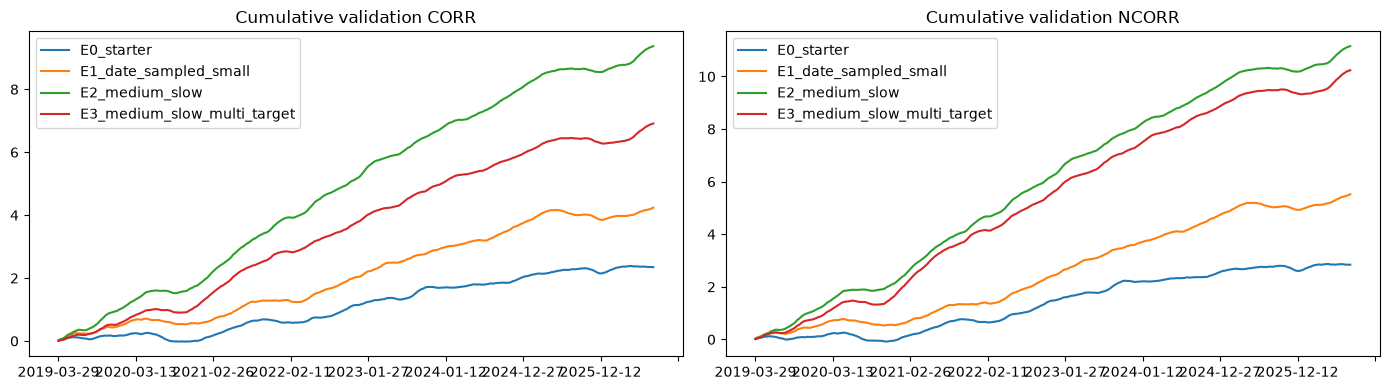

In [12]:
nf = pq.ParquetFile(f"{DATA_VERSION}/validation_neutralizer.parquet")
ncols = [c for c in nf.schema_arrow.names if c.startswith("neutralizer_column_")]
date_idx = nf.schema_arrow.names.index("date")
rg_dates = [
    (nf.metadata.row_group(i).column(date_idx).statistics.min, nf.metadata.row_group(i).column(date_idx).statistics.max)
    for i in range(nf.metadata.num_row_groups)
]

def load_neutralizers(date):
    rgs = [i for i, (a, b) in enumerate(rg_dates) if a <= date <= b]
    n = nf.read_row_groups(rgs, columns=["numerai_ticker", "date"] + ncols).to_pandas()
    return n[n["date"] == date].drop(columns="date").set_index("numerai_ticker")

exp_names = list(trained)
corr_rows, ncorr_rows = {}, {}
for date, d in val.groupby("date"):
    d = d.set_index("numerai_ticker")
    corr_rows[date] = numerai_corr(d[exp_names], d["target"])
    ncorr_rows[date] = neutral_correlation(d[exp_names], load_neutralizers(date), d["target"])
corr = pd.DataFrame(corr_rows).T
ncorr = pd.DataFrame(ncorr_rows).T

def summarize(s):
    c = s.cumsum()
    return pd.Series({
        "mean": s.mean(),
        "std": s.std(ddof=0),
        "sharpe": s.mean() / s.std(ddof=0),
        "positive_dates": (s > 0).mean(),
        "max_drawdown": (c.cummax() - c).max(),
    })

summary = pd.concat(
    {"CORR": corr.apply(summarize), "NCORR": ncorr.apply(summarize)}, axis=1
).T.round(4)
print(summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
corr.cumsum().plot(title="Cumulative validation CORR", ax=axes[0])
ncorr.cumsum().plot(title="Cumulative validation NCORR", ax=axes[1])
plt.tight_layout()
plt.show()

## 6. Final model

The experiment with the highest validation CORR is retrained on training plus validation data (every 4th date), so the submitted model also learns from 2019-2026.

Note: Numerai's diagnostics page scores the 2019-2026 validation period, which this final model has now trained on, so its diagnostics are in-sample and much higher than the held-out scores above. The held-out scores in section 5 are the validation result.

In [13]:
best = corr.mean().idxmax()
print("best by validation CORR:", best)
cfg = experiments[best]
if "train" not in globals():
    train = pd.read_parquet(
        f"{DATA_VERSION}/train.parquet",
        columns=["numerai_ticker", "date", "target"] + AUX_TARGETS + load_features,
        filters=[("date", "in", sampled_dates)],
    )
val_part = val[val["date"].isin(sorted(val["date"].unique())[::4])][train.columns]
full = pd.concat([train, val_part], ignore_index=True)
del train, val_part
final_features = cfg["features"]
final_models = [
    train_model(full, final_features, t, cfg["n_estimators"], cfg["learning_rate"]) for t in cfg["targets"]
]
print(len(final_models), "final models trained on", full["date"].nunique(), "dates")

best by validation CORR: E2_medium_slow
1 final models trained on 306 dates


## 7. Package for submission

Numerai loads this file every round and calls `predict` on the live features. The `.pkl` bundles the function, the trained model(s) and the feature list.

In [14]:
def predict(live_features: pd.DataFrame, live_benchmark_models: pd.DataFrame) -> pd.DataFrame:
    ranks = [
        pd.Series(m.predict(live_features[final_features]), index=live_features.index).rank(pct=True)
        for m in final_models
    ]
    return pd.concat(ranks, axis=1).mean(axis=1).rank(pct=True).to_frame("prediction")

import cloudpickle
with open("improved_numerai.pkl", "wb") as f:
    f.write(cloudpickle.dumps(predict))

Check the file the way Numerai will use it: load it back and predict on the current round's live data. Expect several thousand rows, values in (0, 1], and no missing values.

In [15]:
napi.download_dataset(f"{DATA_VERSION}/live.parquet")
live = pd.read_parquet(f"{DATA_VERSION}/live.parquet")
if "numerai_ticker" in live.columns:
    live = live.set_index("numerai_ticker")
with open("improved_numerai.pkl", "rb") as f:
    loaded_predict = cloudpickle.load(f)
sub = loaded_predict(live, None)
print(sub.shape, sub["prediction"].min(), sub["prediction"].max(), sub["prediction"].isna().sum())
sub.head()

v6.0/live.parquet: 100%|██████████| 4.42M/4.42M [00:00<00:00, 7.01MB/s]


(7112, 1) 0.00014060742407199101 1.0 0


,prediction
numerai_ticker,
000100 KR,0.079303
000120 KR,0.169151
000150 KR,0.920135
000210 KR,0.957677
000240 KR,0.571288


In [16]:
try:
    from google.colab import files
    files.download("improved_numerai.pkl")
except ImportError:
    print("Model saved as", os.path.abspath("improved_numerai.pkl"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload `improved_numerai.pkl` on the model's page at numer.ai. Numerai then submits automatically every round.